# Tarea 1: Algoritmo de *k*-means paralelo

**IMT3870 · Computación de Alto Rendimiento · 2026-4**
Pontificia Universidad Católica de Chile. Magíster en Inteligencia Artificial

**Alumno:** Armando Arredondo Valle
**Profesor:** Ignacio Labarca
**Fecha de entrega:** martes 10 de noviembre de 2026

---

### Contenido

| Parte | Tema | Sección |
|---|---|---|
| (a) | Implementación base con *loops* (código de Canvas) | §2 |
| (b) | Vectorización con NumPy / SciPy | §3 |
| (c) | Medición de tiempo de cómputo, procesos e hilos | §4 |
| (d) | Inercia, método del codo y paralelización con `joblib` | §5 |
| Informe | **Discusión de resultados** | §6 |

### Declaración de uso de herramientas de IA

Para esta tarea se utilizó un asistente de IA (Claude, Anthropic) como apoyo en: la **vectorización**
del algoritmo (uso de `scipy.spatial.distance.cdist`, `np.argmin`, `np.bincount`), la **estructura del
código de medición** (*benchmarks*, gráficos) y la **redacción** del informe. El diseño experimental,
la ejecución en mi equipo, la verificación de consistencia entre implementaciones y la interpretación
de los resultados son propios. Todo el código fue revisado y ejecutado por mí, y soy responsable del
contenido entregado. Se declara conforme a lo permitido en el enunciado.

## 1. Entorno de ejecución y hardware

In [1]:
import sys, os, platform, subprocess, time, copy, json
import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import cdist
from joblib import Parallel, delayed
import psutil

RESULTS = {}   # se guardan las mediciones para el informe

def sysctl(key):
    try:
        return subprocess.check_output(["sysctl","-n",key], text=True).strip()
    except Exception:
        return "n/a"

CPU_BRAND  = sysctl("machdep.cpu.brand_string")
CORES_PHYS = psutil.cpu_count(logical=False)
CORES_LOG  = psutil.cpu_count(logical=True)
CORES_P    = sysctl("hw.perflevel0.physicalcpu")   # performance cores
CORES_E    = sysctl("hw.perflevel1.physicalcpu")   # efficiency cores

print(f"Equipo              : {CPU_BRAND}")
print(f"Sistema             : {platform.platform()}")
print(f"Núcleos FÍSICOS     : {CORES_PHYS}   ({CORES_P} performance + {CORES_E} efficiency)")
print(f"Núcleos LÓGICOS     : {CORES_LOG}")
print(f"Hyperthreading/SMT  : {'sí' if CORES_LOG > CORES_PHYS else 'NO (1 hilo por núcleo físico)'}")
print(f"RAM                 : {psutil.virtual_memory().total/2**30:.0f} GB")
print(f"Python              : {sys.version.split()[0]}  (GIL activo: {getattr(sys,'_is_gil_enabled', lambda: True)()})")
print(f"NumPy / SciPy       : {np.__version__} / {__import__('scipy').__version__}")
print(f"joblib              : {__import__('joblib').__version__}")

RESULTS["hw"] = dict(cpu=CPU_BRAND, phys=CORES_PHYS, log=CORES_LOG,
                     perf=CORES_P, eff=CORES_E, python=sys.version.split()[0])

Equipo              : Apple M5 Pro
Sistema             : macOS-26.6.2-arm64-arm-64bit
Núcleos FÍSICOS     : 15   (5 performance + 10 efficiency)
Núcleos LÓGICOS     : 15
Hyperthreading/SMT  : NO (1 hilo por núcleo físico)
RAM                 : 24 GB
Python              : 3.12.14  (GIL activo: True)
NumPy / SciPy       : 2.5.4 / 1.18.1
joblib              : 1.6.0


In [2]:
# ¿Qué librería de álgebra lineal usa NumPy, y cuántos hilos abre?
# Es relevante para la oversubscription de la Parte (d).
from threadpoolctl import threadpool_info

cfg  = np.__config__.show(mode="dicts")
blas = cfg.get("Build Dependencies", {}).get("blas", {})
BLAS_NAME = blas.get("name", "desconocida")
print(f"BLAS/LAPACK de NumPy : {BLAS_NAME}  (version {blas.get('version','?')})")

pools = threadpool_info()
if pools:
    for pool in pools:
        print(f"   {pool['internal_api']:10s} {pool.get('threading_layer',''):10s} "
              f"num_threads = {pool['num_threads']}")
else:
    print("   threadpoolctl no detecta ningun pool de hilos controlable.")
    print(f"   Esto es lo esperado con '{BLAS_NAME}': Apple Accelerate administra sus hilos")
    print("   internamente y no expone la API (OpenMP/MKL) que threadpoolctl sabe leer.")
    print("   => no se puede fijar el nº de hilos de BLAS con threadpoolctl en este equipo,")
    print("      pero Accelerate SI usa varios hilos (se observa en el pico de CPU de la sec. 4.2).")

RESULTS["blas_name"]    = BLAS_NAME
RESULTS["blas_threads"] = [q["num_threads"] for q in pools]

BLAS/LAPACK de NumPy : accelerate  (version unknown)
   threadpoolctl no detecta ningun pool de hilos controlable.
   Esto es lo esperado con 'accelerate': Apple Accelerate administra sus hilos
   internamente y no expone la API (OpenMP/MKL) que threadpoolctl sabe leer.
   => no se puede fijar el nº de hilos de BLAS con threadpoolctl en este equipo,
      pero Accelerate SI usa varios hilos (se observa en el pico de CPU de la sec. 4.2).


## 2. Parte (a): datos e implementación base (código de Canvas)

Se genera la base de datos con `make_blobs` (única función de `sklearn` permitida por el enunciado) y
se ejecuta la implementación entregada en Canvas, basada en *loops* de Python.

Según el enunciado se usan **al menos 10.000 puntos** y **k ≥ 5**.

In [3]:
np.random.seed(0)          # semilla fija: resultados reproducibles

from sklearn.datasets import make_blobs

n_points   = 10_000        # ≥ 10.000 por enunciado
n_blobs    = 10            # grupos realmente generados
k          = 5             # ≥ 5 por enunciado
max_iterations = 100
d          = 2

dataset, _true_labels = make_blobs(n_samples=n_points, n_features=d, centers=n_blobs)
print(f"Base de datos: {dataset.shape[0]:,} puntos en {dataset.shape[1]} dimensiones, "
      f"generados en {n_blobs} grupos.")
print(f"Memoria del arreglo: {dataset.nbytes/1024:.1f} KiB  (dtype={dataset.dtype})")
print(f"Valor de k para las partes (a)-(c): {k}")

Base de datos: 10,000 puntos en 2 dimensiones, generados en 10 grupos.
Memoria del arreglo: 156.2 KiB  (dtype=float64)
Valor de k para las partes (a)-(c): 5


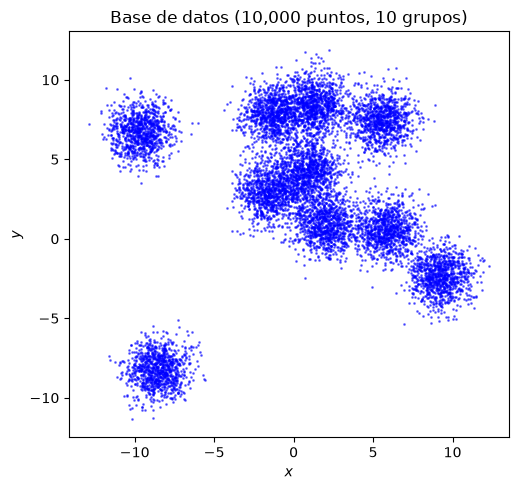

In [4]:
plt.figure(figsize=(6,5))
plt.plot(dataset[:,0], dataset[:,1], 'b.', markersize=2, alpha=.5)
plt.title(f'Base de datos ({n_points:,} puntos, {n_blobs} grupos)')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.gca().set_aspect('equal')
plt.tight_layout(); plt.show()

### 2.1 Inicialización

Igual que en el ejemplo de Canvas: los $k$ centros iniciales se distribuyen uniformemente en el
segmento $0<x<1$, $y=0$. Es una inicialización deliberadamente *mala* (todos los centros quedan
pegados al origen, lejos de los *blobs*), lo que obliga al algoritmo a iterar varias veces y hace más
visible el costo de cómputo.

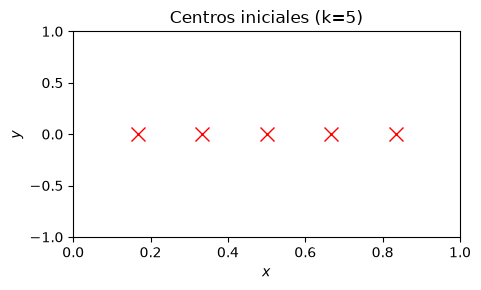

In [5]:
def init_centers(k):
    "Centros iniciales del enunciado: uniformes en 0<x<1, y=0."
    centers = np.zeros([k, 2])
    for c in range(k):
        centers[c, 0] = float(c+1)/(k+1)
        centers[c, 1] = 0.0
    return centers

centers0 = init_centers(k)
plt.figure(figsize=(5,3))
plt.plot(centers0[:,0], centers0[:,1], 'rx', markersize=10)
plt.xlim([0,1]); plt.ylim([-1,1]); plt.title(f'Centros iniciales (k={k})')
plt.xlabel('$x$'); plt.ylabel('$y$'); plt.tight_layout(); plt.show()

### 2.2 Implementación con *loops*

Es el código de Canvas, encapsulado en una función para poder reutilizarlo (medirlo y enviarlo como
tarea a `joblib`). Se conserva **exactamente** la estructura de *loops* sobre los puntos.

**Una corrección necesaria.** El código original calcula el nuevo centro como
`sum_of_locations[c,0] / number_of_points_in_cluster[c]`. Si una conglomeración queda **vacía**,
`number_of_points_in_cluster[c] == 0` y esa división produce `nan` (y un `RuntimeWarning`), lo que
contamina todas las iteraciones siguientes. Con la inicialización del enunciado esto **sí ocurre**
para algunos valores de $k$ del barrido de la Parte (d). La convención usual es **mantener el centro
anterior** cuando una conglomeración queda vacía, y es lo que se hace aquí (se cuentan los casos para
reportarlos).

In [6]:
def kmeans_loops(dataset, k, max_iterations=100, keep_history=False):
    '''
    k-means con loops de Python (implementación base de Canvas).
    Devuelve dict con centros, etiquetas, nº de iteraciones y diagnóstico.
    '''
    n_points = dataset.shape[0]
    history_of_centers  = [init_centers(k)]
    history_of_clusters = []
    empty_fixes = 0
    converged   = False

    for iteration in range(max_iterations):

        old_centers = history_of_centers[-1]

        # ---- paso de asignación (loop sobre TODOS los puntos) ----
        cluster = np.zeros(n_points, dtype='int')
        for p in range(n_points):
            minimum_distance = np.inf
            nearest_cluster  = None
            for c in range(k):
                distance_to_cluster_c = np.sqrt((dataset[p,0] - old_centers[c,0])**2
                                                + (dataset[p,1] - old_centers[c,1])**2)
                if distance_to_cluster_c < minimum_distance:
                    minimum_distance = distance_to_cluster_c
                    nearest_cluster  = c
            cluster[p] = nearest_cluster
        history_of_clusters.append(cluster)

        # ---- revisar convergencia (otro loop sobre los puntos) ----
        if iteration > 0:
            clusters_changed = False
            for p in range(n_points):
                if history_of_clusters[-1][p] != history_of_clusters[-2][p]:
                    clusters_changed = True
            if not clusters_changed:
                converged = True
                break

        # ---- paso de actualización (loop sobre los puntos) ----
        number_of_points_in_cluster = np.zeros(k, dtype='int')
        sum_of_locations = np.zeros([k, 2], dtype='float')
        for p in range(n_points):
            number_of_points_in_cluster[cluster[p]] += 1
            sum_of_locations[cluster[p], :] += dataset[p, :]

        new_centers = np.zeros([k, 2], dtype='float')
        for c in range(k):
            if number_of_points_in_cluster[c] == 0:
                new_centers[c, :] = old_centers[c, :]      # conglomeración vacía
                empty_fixes += 1
            else:
                new_centers[c,0] = sum_of_locations[c,0] / number_of_points_in_cluster[c]
                new_centers[c,1] = sum_of_locations[c,1] / number_of_points_in_cluster[c]
        history_of_centers.append(new_centers)

    out = dict(centers=history_of_centers[-1], labels=history_of_clusters[-1],
               iterations=iteration, converged=converged, empty_fixes=empty_fixes,
               pid=os.getpid())
    if keep_history:
        out["history_of_centers"]  = history_of_centers
        out["history_of_clusters"] = history_of_clusters
    return out

In [7]:
t0 = time.perf_counter()
res_loops = kmeans_loops(dataset, k, max_iterations, keep_history=True)
t_loops = time.perf_counter() - t0

print(f"Tiempo de cómputo (loops) : {t_loops:.3f} s")
print(f"Iteraciones               : {res_loops['iterations']}"
      f"  ({'convergió' if res_loops['converged'] else 'NO convergió, se alcanzó el máximo'})")
print(f"Conglomeraciones vacías   : {res_loops['empty_fixes']}")
print(f"Centros finales:\n{res_loops['centers']}")
RESULTS["t_loops_k5"] = t_loops
RESULTS["iters_k5"]   = res_loops["iterations"]

Tiempo de cómputo (loops) : 0.285 s
Iteraciones               : 12  (convergió)
Conglomeraciones vacías   : 0
Centros finales:
[[-8.5481891  -8.22911697]
 [-9.59496645  6.73334894]
 [ 1.88408512  7.80218673]
 [ 0.41720578  2.54300103]
 [ 7.56297949 -0.93033615]]


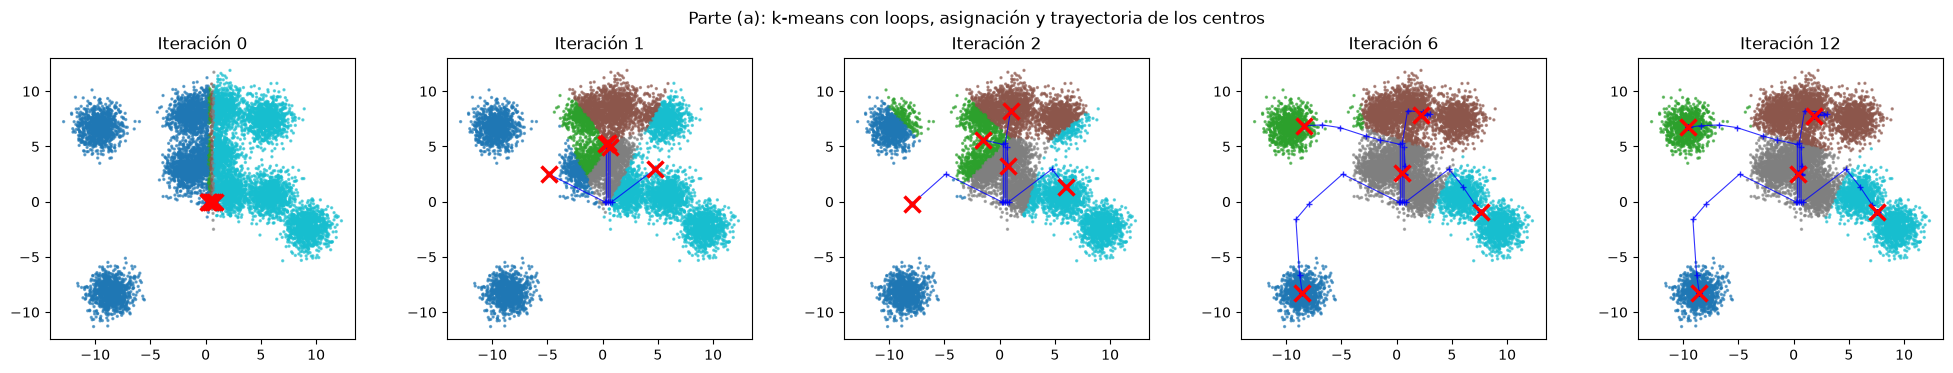

In [8]:
# Evolución: etiquetas finales y trayectoria de los centros
hc, hcl = res_loops["history_of_centers"], res_loops["history_of_clusters"]
show = [0, 1, 2, len(hcl)//2, len(hcl)-1]
show = sorted(set(i for i in show if i < len(hcl)))

fig, axes = plt.subplots(1, len(show), figsize=(4*len(show), 3.6))
for ax, itr in zip(np.atleast_1d(axes), show):
    ax.scatter(dataset[:,0], dataset[:,1], c=hcl[itr], s=2, cmap='tab10', alpha=.6)
    traj = np.array([hc[l] for l in range(itr+1)])
    for c in range(k):
        ax.plot(traj[:,c,0], traj[:,c,1], 'b-+', lw=.8, markersize=4, alpha=.8)
    ax.plot(hc[itr][:,0], hc[itr][:,1], 'rx', markersize=11, mew=2.5)
    ax.set_title(f'Iteración {itr}'); ax.set_aspect('equal')
plt.suptitle('Parte (a): k-means con loops, asignación y trayectoria de los centros')
plt.tight_layout(); plt.show()

### 2.3 ¿Paraleliza algo este código? Medición de procesos e hilos

Para responder la pregunta (1) del informe no basta razonar: se **mide**. Se observa el número de
hilos del proceso de Python y el uso de CPU **mientras** corre el algoritmo con *loops*. Si el código
estuviera paralelizado, el uso de CPU debería superar el 100 % de un núcleo.

In [9]:
proc = psutil.Process()

THREADS_BASELINE = proc.num_threads()
print(f"Hilos del kernel de Jupyter en reposo (linea base): {THREADS_BASELINE}")

def watch_cpu(fn, *args, min_duration=1.0, **kw):
    '''
    Ejecuta fn midiendo %CPU y nº de hilos del proceso (muestreo en un hilo aparte).
    Si fn es muy rápida, la repite hasta acumular min_duration segundos, de modo que
    el muestreador alcance a tomar muestras.
    '''
    import threading
    samples = {"cpu": [], "threads": []}
    stop = threading.Event()
    def sampler():
        proc.cpu_percent(None)                     # primera llamada: inicializa
        while not stop.wait(0.005):
            samples["cpu"].append(proc.cpu_percent(None))
            samples["threads"].append(proc.num_threads())
    th = threading.Thread(target=sampler, daemon=True); th.start()
    try:
        t0 = time.perf_counter(); n_calls = 0
        while True:
            out = fn(*args, **kw); n_calls += 1
            if time.perf_counter() - t0 >= min_duration: break
    finally:
        stop.set(); th.join()
    cpu = [c for c in samples["cpu"] if c > 0]
    return (out, (max(cpu) if cpu else 0.0), (np.mean(cpu) if cpu else 0.0),
            max(samples["threads"] or [0]), n_calls)

_, cpu_max, cpu_avg, n_threads, _nc = watch_cpu(kmeans_loops, dataset, k, max_iterations)

print(f"Procesos de Python activos        : 1  (PID {os.getpid()}, sin procesos hijos: "
      f"{len(proc.children(recursive=True))})")
print(f"Hilos del proceso (máximo)        : {n_threads}  "
      f"(= {THREADS_BASELINE} del kernel de Jupyter + 1 de esta medición)")
print(f"Hilos creados por el ALGORITMO    : {max(0, n_threads - THREADS_BASELINE - 1)}")
print(f"Uso de CPU del proceso  promedio  : {cpu_avg:6.1f} %")
print(f"Uso de CPU del proceso  máximo    : {cpu_max:6.1f} %")
print(f"Núcleos físicos disponibles       : {CORES_PHYS}  "
      f"(uso total posible: {100*CORES_PHYS} %)")
print()
print(f"=> El algoritmo usa ~1 núcleo de {CORES_PHYS}: "
      f"{cpu_avg/(100*CORES_PHYS)*100:.1f} % de la capacidad de la máquina.")
RESULTS["cpu_avg_loops"] = cpu_avg; RESULTS["cpu_max_loops"] = cpu_max
RESULTS["threads_loops"] = n_threads

Hilos del kernel de Jupyter en reposo (linea base): 16


Procesos de Python activos        : 1  (PID 32468, sin procesos hijos: 0)
Hilos del proceso (máximo)        : 17  (= 16 del kernel de Jupyter + 1 de esta medición)
Hilos creados por el ALGORITMO    : 0
Uso de CPU del proceso  promedio  :   99.9 %
Uso de CPU del proceso  máximo    :  100.8 %
Núcleos físicos disponibles       : 15  (uso total posible: 1500 %)

=> El algoritmo usa ~1 núcleo de 15: 6.7 % de la capacidad de la máquina.


## 3. Parte (b): vectorización

Requisitos del enunciado:

* usar **arreglos** en lugar de listas;
* usar **funciones vectoriales** de NumPy/SciPy (normas, distancias, sumas);
* **ningún loop ni *list comprehension* sobre los puntos**; se permiten loops sobre los centros;
* solo NumPy/SciPy (sin `sklearn`, `pandas`, etc.), excepto `make_blobs`.

Las tres partes del algoritmo se reemplazan así:

| Paso | Con loops | Vectorizado |
|---|---|---|
| Asignación | loop `p` × loop `c` + `sqrt` escalar | `cdist(dataset, centers)` + `np.argmin(..., axis=1)` |
| Convergencia | loop `p` comparando etiquetas | `np.array_equal(cluster, prev)` |
| Actualización | loop `p` acumulando sumas | `np.add.at` / máscara `dataset[cluster==c].mean(0)` + `np.bincount` |

Para el paso de actualización se usa un loop **sobre los k centros** (permitido), no sobre los puntos.
Se emplea `np.bincount` para contar los puntos por conglomeración y `np.add.at` para acumular las
sumas de coordenadas en una sola pasada vectorial.

In [10]:
def kmeans_numpy(dataset, k, max_iterations=100, keep_history=False):
    '''
    k-means vectorizado con NumPy/SciPy.
    Sin loops ni list comprehensions sobre los n puntos; solo loops sobre los k centros.
    '''
    centers = init_centers(k)
    history_of_centers  = [centers]
    history_of_clusters = []
    previous_cluster = None
    empty_fixes = 0
    converged   = False

    for iteration in range(max_iterations):

        # ---- paso de asignación: matriz de distancias (n x k) y argmin por fila ----
        distances = cdist(dataset, centers, metric='euclidean')   # SciPy, código compilado
        cluster   = np.argmin(distances, axis=1)
        history_of_clusters.append(cluster)

        # ---- convergencia: comparación vectorial de los arreglos de etiquetas ----
        if previous_cluster is not None and np.array_equal(cluster, previous_cluster):
            converged = True
            break
        previous_cluster = cluster

        # ---- paso de actualización: centro de masa por conglomeración ----
        counts = np.bincount(cluster, minlength=k)                # puntos por cluster
        sums   = np.zeros((k, dataset.shape[1]))
        np.add.at(sums, cluster, dataset)                         # suma vectorial por cluster

        new_centers = centers.copy()
        nonempty = counts > 0
        new_centers[nonempty] = sums[nonempty] / counts[nonempty, None]   # centro de masa
        empty_fixes += int(np.count_nonzero(~nonempty))            # vacías: se mantiene el centro

        centers = new_centers
        history_of_centers.append(centers)

    out = dict(centers=centers, labels=history_of_clusters[-1], iterations=iteration,
               converged=converged, empty_fixes=empty_fixes, pid=os.getpid())
    if keep_history:
        out["history_of_centers"]  = history_of_centers
        out["history_of_clusters"] = history_of_clusters
    return out

### 3.1 Verificación de consistencia con la implementación base

In [11]:
res_numpy = kmeans_numpy(dataset, k, max_iterations, keep_history=True)

same_labels  = np.array_equal(res_loops["labels"], res_numpy["labels"])
agreement    = np.mean(res_loops["labels"] == res_numpy["labels"]) * 100
max_dc       = np.abs(np.sort(res_loops["centers"],0) - np.sort(res_numpy["centers"],0)).max()
same_iters   = res_loops["iterations"] == res_numpy["iterations"]

print(f"Iteraciones  loops / numpy   : {res_loops['iterations']} / {res_numpy['iterations']}"
      f"   {'✓ iguales' if same_iters else '✗ distintas'}")
print(f"Etiquetas idénticas          : {'✓ SÍ' if same_labels else '✗ no'}  "
      f"(coincidencia {agreement:.4f} %)")
print(f"Máx. diferencia en centros   : {max_dc:.3e}")
print(f"Conglomeraciones vacías      : loops={res_loops['empty_fixes']}, numpy={res_numpy['empty_fixes']}")
assert same_labels, "Las implementaciones deben dar el mismo resultado"
print("\n=> Las dos implementaciones son CONSISTENTES: mismas etiquetas y mismos centros.")
RESULTS["consistent"] = bool(same_labels); RESULTS["agreement_pct"] = agreement
RESULTS["max_center_diff"] = float(max_dc)

Iteraciones  loops / numpy   : 12 / 12   ✓ iguales
Etiquetas idénticas          : ✓ SÍ  (coincidencia 100.0000 %)
Máx. diferencia en centros   : 0.000e+00
Conglomeraciones vacías      : loops=0, numpy=0

=> Las dos implementaciones son CONSISTENTES: mismas etiquetas y mismos centros.


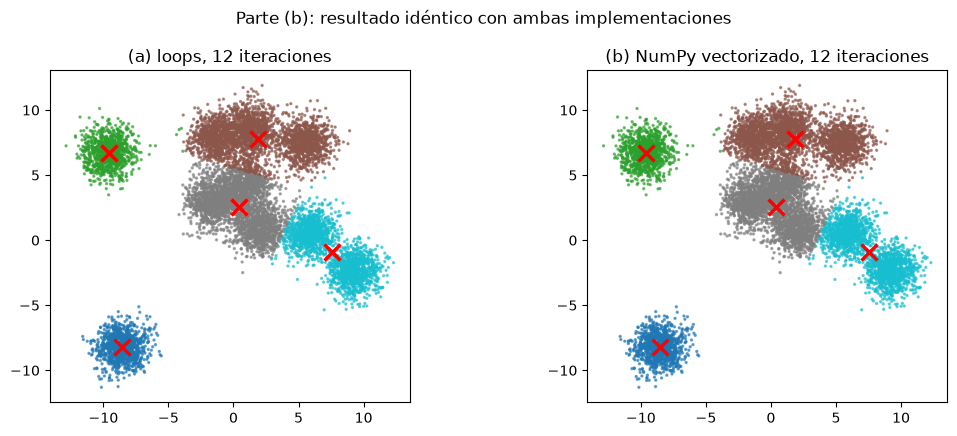

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (res, name) in zip(axes, [(res_loops,'(a) loops'), (res_numpy,'(b) NumPy vectorizado')]):
    ax.scatter(dataset[:,0], dataset[:,1], c=res["labels"], s=2, cmap='tab10', alpha=.6)
    ax.plot(res["centers"][:,0], res["centers"][:,1], 'rx', markersize=12, mew=2.5)
    ax.set_title(f'{name}, {res["iterations"]} iteraciones'); ax.set_aspect('equal')
plt.suptitle('Parte (b): resultado idéntico con ambas implementaciones')
plt.tight_layout(); plt.show()

## 4. Parte (c): medición del tiempo de cómputo

Se mide cada implementación repetidas veces (se reporta el **mínimo**, que es la estimación menos
contaminada por ruido del sistema operativo) y se estudia cómo escala el tiempo con el número de
puntos $n$.

In [13]:
def bench(fn, *args, repeats=3, **kw):
    "Devuelve (mejor tiempo, tiempo medio) de varias repeticiones."
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(*args, **kw); ts.append(time.perf_counter()-t0)
    return min(ts), float(np.mean(ts))

t_loops_best, t_loops_mean = bench(kmeans_loops, dataset, k, max_iterations, repeats=3)
t_numpy_best, t_numpy_mean = bench(kmeans_numpy, dataset, k, max_iterations, repeats=7)
speedup = t_loops_best / t_numpy_best

print(f"{'Implementación':<28} {'mejor [s]':>12} {'medio [s]':>12}")
print("-"*54)
print(f"{'(a) loops de Python':<28} {t_loops_best:>12.4f} {t_loops_mean:>12.4f}")
print(f"{'(b) NumPy vectorizado':<28} {t_numpy_best:>12.4f} {t_numpy_mean:>12.4f}")
print("-"*54)
print(f"\nAceleración por vectorizar: {speedup:.1f}x   "
      f"(n = {n_points:,} puntos, k = {k}, {res_loops['iterations']} iteraciones)")
print(f"Tiempo por punto y por iteración:")
print(f"   loops : {t_loops_best/(n_points*res_loops['iterations'])*1e9:8.1f} ns")
print(f"   numpy : {t_numpy_best/(n_points*res_numpy['iterations'])*1e9:8.1f} ns")
RESULTS.update(t_loops_best=t_loops_best, t_numpy_best=t_numpy_best, speedup_vec=speedup)

Implementación                  mejor [s]    medio [s]
------------------------------------------------------
(a) loops de Python                0.2728       0.2865
(b) NumPy vectorizado              0.0041       0.0043
------------------------------------------------------

Aceleración por vectorizar: 66.4x   (n = 10,000 puntos, k = 5, 12 iteraciones)
Tiempo por punto y por iteración:
   loops :   2273.7 ns
   numpy :     34.2 ns


### 4.1 Escalamiento con el número de puntos

In [14]:
sizes = [1_000, 2_500, 5_000, 10_000, 20_000, 40_000]
tl, tn = [], []
for n in sizes:
    sub = dataset[:n] if n <= n_points else None
    if sub is None:
        np.random.seed(0)
        sub, _ = make_blobs(n_samples=n, n_features=2, centers=n_blobs)
    a,_ = bench(kmeans_loops, sub, k, max_iterations, repeats=1)
    b,_ = bench(kmeans_numpy, sub, k, max_iterations, repeats=3)
    tl.append(a); tn.append(b)
    print(f"n = {n:6,} | loops {a:8.3f} s | numpy {b:8.4f} s | speedup {a/b:6.1f}x")
RESULTS["scaling"] = dict(sizes=sizes, loops=tl, numpy=tn)

n =  1,000 | loops    0.025 s | numpy   0.0005 s | speedup   55.3x
n =  2,500 | loops    0.071 s | numpy   0.0012 s | speedup   58.7x


n =  5,000 | loops    0.158 s | numpy   0.0024 s | speedup   64.7x


n = 10,000 | loops    0.313 s | numpy   0.0043 s | speedup   73.4x


n = 20,000 | loops    0.823 s | numpy   0.0128 s | speedup   64.5x


n = 40,000 | loops    1.610 s | numpy   0.0369 s | speedup   43.6x


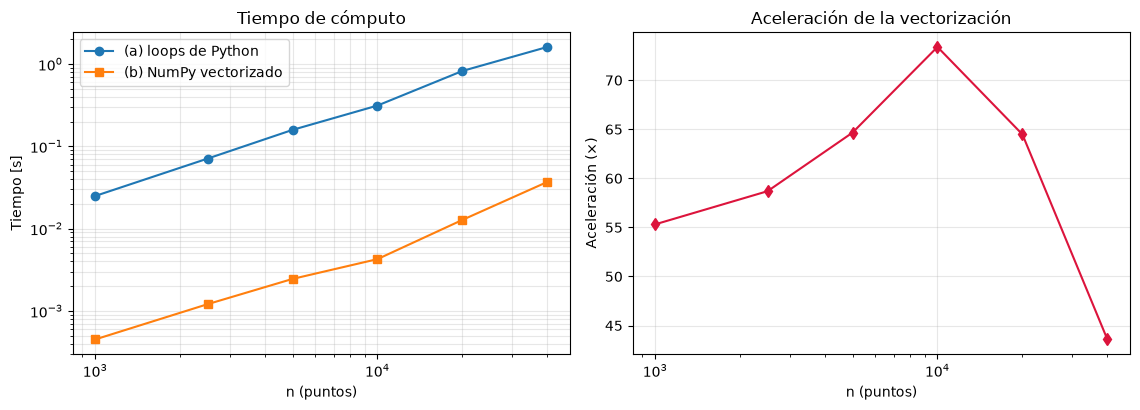

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].loglog(sizes, tl, 'o-', label='(a) loops de Python')
axes[0].loglog(sizes, tn, 's-', label='(b) NumPy vectorizado')
axes[0].set_xlabel('n (puntos)'); axes[0].set_ylabel('Tiempo [s]')
axes[0].set_title('Tiempo de cómputo'); axes[0].legend(); axes[0].grid(True, which='both', alpha=.3)
axes[1].semilogx(sizes, np.array(tl)/np.array(tn), 'd-', color='crimson')
axes[1].set_xlabel('n (puntos)'); axes[1].set_ylabel('Aceleración (×)')
axes[1].set_title('Aceleración de la vectorización'); axes[1].grid(True, alpha=.3)
plt.tight_layout(); plt.show()

### 4.2 Procesos e hilos durante la ejecución

Se compara el uso de CPU e hilos de las dos implementaciones. Esto permite ver si NumPy/SciPy abren
hilos adicionales (BLAS) en esta carga de trabajo.

In [16]:
rows = []
for name, fn in [("(a) loops", kmeans_loops), ("(b) NumPy", kmeans_numpy)]:
    _, cmax, cavg, nth, ncalls = watch_cpu(fn, dataset, k, max_iterations, min_duration=1.5)
    rows.append((name, cavg, cmax, nth, ncalls))

print(f"{'Implementación':<14} {'CPU medio':>11} {'CPU máx':>10} {'hilos':>7} {'corridas':>10}")
print("-"*58)
for name, cavg, cmax, nth, ncalls in rows:
    print(f"{name:<14} {cavg:>10.1f} % {cmax:>9.1f} % {nth:>7} {ncalls:>10}")
print("-"*58)
print("(1 núcleo = 100 %. La version NumPy se repite muchas veces en la ventana de")
print(" medicion porque una sola corrida dura pocos milisegundos.)")
print(f"\nNúcleos físicos: {CORES_PHYS}.  Capacidad total de la máquina: {100*CORES_PHYS} %.")
print("Ninguna de las dos implementaciones supera ~100 %: ambas son esencialmente SECUENCIALES.")
print(f"\nProcesos hijos de Python en este momento: {len(proc.children(recursive=True))}")
RESULTS["cpu_table"] = [(n, float(a), float(m), int(t), int(c)) for n,a,m,t,c in rows]

Implementación   CPU medio    CPU máx   hilos   corridas
----------------------------------------------------------
(a) loops            98.5 %     100.4 %      17          6
(b) NumPy            98.4 %     247.8 %      17        335
----------------------------------------------------------
(1 núcleo = 100 %. La version NumPy se repite muchas veces en la ventana de
 medicion porque una sola corrida dura pocos milisegundos.)

Núcleos físicos: 15.  Capacidad total de la máquina: 1500 %.
Ninguna de las dos implementaciones supera ~100 %: ambas son esencialmente SECUENCIALES.

Procesos hijos de Python en este momento: 0


## 5. Parte (d): inercia, método del codo y paralelización con `joblib`

### 5.1 Inercia

$$I_k=\sum_{i=1}^{k}\sum_{j=1}^{N_i}\lVert \mathbf{x}_{ij}-\mathbf{c}_i\rVert^2$$

Se calcula de forma vectorizada: la inercia es la suma de las distancias al cuadrado de cada punto
al centro **asignado**, es decir `((dataset - centers[labels])**2).sum()`.

In [17]:
def inertia(dataset, labels, centers):
    "Inercia I_k, totalmente vectorizada (sin loops sobre los puntos)."
    diff = dataset - centers[labels]
    return float(np.einsum('ij,ij->', diff, diff))     # == (diff**2).sum()

def inertia_reference(datapoints, cluster, centers):
    "Versión del ejemplo de Canvas, con loop sobre los k centros (para verificar)."
    total = 0.0
    for i in range(centers.shape[0]):
        pts = datapoints[cluster == i, :]
        if pts.size:
            total += np.sum(np.linalg.norm(pts - centers[i,:], axis=1)**2)
    return total

I_fast = inertia(dataset, res_numpy["labels"], res_numpy["centers"])
I_ref  = inertia_reference(dataset, res_numpy["labels"], res_numpy["centers"])
print(f"Inercia (vectorizada)      : {I_fast:,.4f}")
print(f"Inercia (versión de Canvas): {I_ref:,.4f}")
print(f"Diferencia relativa        : {abs(I_fast-I_ref)/I_ref:.2e}  ✓ coinciden")

Inercia (vectorizada)      : 64,256.3365
Inercia (versión de Canvas): 64,256.3365
Diferencia relativa        : 6.79e-16  ✓ coinciden


### 5.2 Tarea para `joblib`: un valor de k por tarea

Cada tarea corre **todo** el algoritmo de k-means para un único $k$ y devuelve la inercia junto con el
**PID** del proceso que la ejecutó (para comprobar que `joblib` efectivamente usa procesos distintos,
bajo el paradigma *multiprocessing*).

Las funciones se definen a nivel de módulo para que sean **serializables** (`pickle`), como requiere el
modelo `spawn` que usa `loky` por defecto (Clase 04).

In [18]:
def kmeans_task(dataset, k, max_iterations=100, impl="numpy"):
    "Una tarea de joblib: k-means completo para un único k. Devuelve inercia, PID y diagnóstico."
    t0  = time.perf_counter()
    res = (kmeans_numpy if impl == "numpy" else kmeans_loops)(dataset, k, max_iterations)
    return dict(k=k, inertia=inertia(dataset, res["labels"], res["centers"]),
                iterations=res["iterations"], converged=res["converged"],
                empty=res["empty_fixes"], pid=os.getpid(),
                t=time.perf_counter()-t0)

ks = list(range(1, 26))        # k = 1, 2, ..., 25
print("k =", ks)

k = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


### 5.3 Barrido serial y método del codo

In [19]:
t0 = time.perf_counter()
sweep = [kmeans_task(dataset, kk, max_iterations, impl="numpy") for kk in ks]
t_sweep_serial_numpy = time.perf_counter() - t0

inertias = [s["inertia"] for s in sweep]
print(f"Barrido serial k=1..25 (NumPy): {t_sweep_serial_numpy:.3f} s")
print(f"PIDs utilizados: {sorted({s['pid'] for s in sweep})}  -> un solo proceso (serial)")
no_conv = [s['k'] for s in sweep if not s['converged']]
print(f"Valores de k que NO convergieron en {max_iterations} iteraciones: {no_conv}")
print(f"Valores de k con conglomeraciones vacías: {[s['k'] for s in sweep if s['empty']>0]}")
RESULTS["t_sweep_serial_numpy"] = t_sweep_serial_numpy
RESULTS["inertias"] = inertias
RESULTS["no_converged"] = no_conv
RESULTS["empty_ks"] = [s['k'] for s in sweep if s['empty']>0]

Barrido serial k=1..25 (NumPy): 0.576 s
PIDs utilizados: [32468]  -> un solo proceso (serial)
Valores de k que NO convergieron en 100 iteraciones: [22, 23, 25]
Valores de k con conglomeraciones vacías: [11, 15, 23]


Criterio 1 - cuerda sobre log(I)          : k = 10
Criterio 2 - 1er k con ganancia < 10 %     : k = 10
Criterio ingenuo - max. 2a diferencia     : k = 2   <-- enganoso (ver informe)
Grupos realmente generados por make_blobs : 10


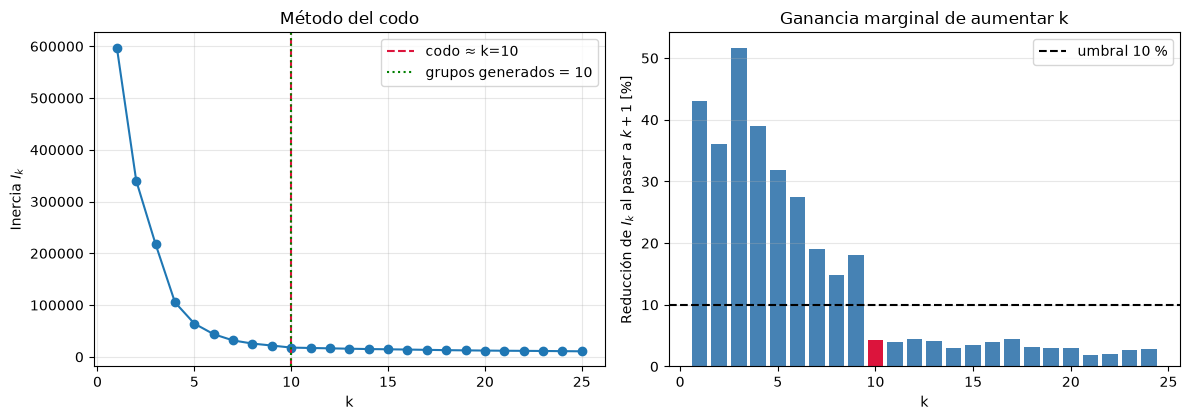

La inercia SIEMPRE decrece al aumentar k (Clase 04): por eso no se puede
minimizar I_k directamente, y hay que buscar el punto de inflexion.

  k -> k+1    ganancia
-----------------------
   1 ->  2     43.07 %
   2 ->  3     36.03 %
   3 ->  4     51.60 %
   4 ->  5     39.00 %
   5 ->  6     31.86 %
   6 ->  7     27.47 %
   7 ->  8     19.07 %
   8 ->  9     14.85 %
   9 -> 10     18.10 %
  10 -> 11      4.24 %   <-- codo
  11 -> 12      3.96 %
  12 -> 13      4.42 %
  13 -> 14      4.16 %
  14 -> 15      3.03 %
  15 -> 16      3.52 %
  16 -> 17      3.97 %
  17 -> 18      4.43 %
  18 -> 19      3.12 %
  19 -> 20      2.94 %
  20 -> 21      2.93 %
  21 -> 22      1.83 %
  22 -> 23      2.08 %
  23 -> 24      2.75 %
  24 -> 25      2.84 %


In [20]:
# ---- Método del codo: dos criterios cuantitativos ----
I   = np.array(inertias)
kv  = np.array(ks)
rel = -np.diff(I) / I[:-1] * 100            # reducción RELATIVA al pasar de k a k+1 [%]

# Criterio 1 (cuerda / "Kneedle"): el punto más alejado de la recta que une los
# extremos de la curva. Se aplica sobre log(I) porque la inercia cae varios
# órdenes de magnitud y en escala lineal el criterio se sesga hacia k pequeños.
xn  = (kv - kv.min()) / (kv.max() - kv.min())
yl  = np.log(I); yln = (yl - yl.min()) / (yl.max() - yl.min())
k_chord = int(kv[np.argmin(xn + yln)])

# Criterio 2: primer k cuya ganancia marginal cae por debajo de un umbral.
UMBRAL = 10.0
below   = np.where(rel < UMBRAL)[0]
k_thr   = int(kv[below[0]]) if below.size else int(kv[-1])

# Criterio ingenuo, para contraste: máxima segunda diferencia.
k_naive = int(kv[1:-1][np.argmax(np.diff(I, 2))])

k_elbow = k_chord
print(f"Criterio 1 - cuerda sobre log(I)          : k = {k_chord}")
print(f"Criterio 2 - 1er k con ganancia < {UMBRAL:.0f} %     : k = {k_thr}")
print(f"Criterio ingenuo - max. 2a diferencia     : k = {k_naive}   <-- enganoso (ver informe)")
print(f"Grupos realmente generados por make_blobs : {n_blobs}")
RESULTS.update(k_chord=k_chord, k_thr=k_thr, k_naive=k_naive)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(ks, I, 'o-')
axes[0].axvline(k_elbow, color='crimson', ls='--', label=f'codo ≈ k={k_elbow}')
axes[0].axvline(n_blobs, color='green', ls=':', label=f'grupos generados = {n_blobs}')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inercia $I_k$')
axes[0].set_title('Método del codo'); axes[0].legend(); axes[0].grid(alpha=.3)
axes[0].set_xticks(range(0,26,5))

axes[1].bar(kv[:-1], rel, color=['crimson' if a == k_elbow else 'steelblue' for a in kv[:-1]])
axes[1].axhline(UMBRAL, color='k', ls='--', label=f'umbral {UMBRAL:.0f} %')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Reducción de $I_k$ al pasar a $k+1$ [%]')
axes[1].set_title('Ganancia marginal de aumentar k')
axes[1].legend(); axes[1].grid(alpha=.3, axis='y'); axes[1].set_xticks(range(0,26,5))
plt.tight_layout(); plt.show()

print("La inercia SIEMPRE decrece al aumentar k (Clase 04): por eso no se puede")
print("minimizar I_k directamente, y hay que buscar el punto de inflexion.\n")
print(f"{'k -> k+1':>10} {'ganancia':>11}")
print("-"*23)
for a, r in zip(kv[:-1], rel):
    print(f"{a:4d} ->{a+1:3d} {r:9.2f} %" + ("   <-- codo" if a == k_elbow else ""))
RESULTS["k_elbow"] = k_elbow

### 5.4 Paralelización con `joblib`: verificación de procesos distintos

Se usa el *backend* `loky` (el de por omisión de `joblib`), que crea **procesos independientes**:
es el paradigma *multiprocessing* pedido por el enunciado. Se verifica recolectando los PID.

In [21]:
out4 = Parallel(n_jobs=4, backend="loky")(
            delayed(kmeans_task)(dataset, kk, max_iterations, "numpy") for kk in ks)
pids = sorted({o["pid"] for o in out4})

print(f"PID del proceso padre : {os.getpid()}")
print(f"PIDs de los workers   : {pids}")
print(f"Nº de procesos distintos usados: {len(pids)}  (n_jobs=4)")
print(f"¿Usa procesos distintos del padre? {'✓ SÍ' if os.getpid() not in pids else '✗ no'}")

same = np.allclose([o["inertia"] for o in out4], inertias)
print(f"\n¿Mismas inercias que el barrido serial? {'✓ SÍ' if same else '✗ NO'}")
RESULTS["n_pids_njobs4"] = len(pids)
RESULTS["parallel_same_result"] = bool(same)

PID del proceso padre : 32468
PIDs de los workers   : [32703, 32704, 32705, 32706]
Nº de procesos distintos usados: 4  (n_jobs=4)
¿Usa procesos distintos del padre? ✓ SÍ

¿Mismas inercias que el barrido serial? ✓ SÍ


### 5.5 Tiempo de cómputo vs. número de procesos

Se repite el barrido completo $k=1,\dots,25$ para `n_jobs` $=1,2,3,4$ (y además 8 y 15, el número de
núcleos físicos de este equipo), con **dos tareas distintas**, como pide la pregunta (3) del informe:

1. la tarea es k-means implementado con **loops**;
2. la tarea es k-means implementado con **NumPy**.

In [22]:
n_jobs_list = sorted(set([1, 2, 3, 4, 8, CORES_PHYS]))
timings  = {"loops": {}, "numpy": {}}
per_task = {}
REPEATS  = {"numpy": 3, "loops": 1}   # la tarea NumPy dura ms: se repite y se toma el minimo

for impl in ["numpy", "loops"]:
    print(f"\n### Tarea = k-means con {impl}  " + "#"*30)
    print(f"{'n_jobs':>7} {'tiempo [s]':>12} {'speedup':>10} {'eficiencia':>12} {'procesos':>10}")
    print("-"*56)
    for p in n_jobs_list:
        best = np.inf
        for _ in range(REPEATS[impl]):
            t0 = time.perf_counter()
            out = Parallel(n_jobs=p, backend="loky")(
                      delayed(kmeans_task)(dataset, kval, max_iterations, impl) for kval in ks)
            best = min(best, time.perf_counter() - t0)
        npid = len({o["pid"] for o in out})
        timings[impl][p] = best
        if p == 1:
            per_task[impl] = [o["t"] for o in out]
        sp = timings[impl][1] / best
        print(f"{p:>7} {best:>12.3f} {sp:>9.2f}x {sp/p*100:>11.1f} % {npid:>10}")

RESULTS["timings"]  = {i: {str(a): b for a, b in d.items()} for i, d in timings.items()}
RESULTS["per_task"] = {i: [float(x) for x in v] for i, v in per_task.items()}

RESULTS["timings"] = {i: {str(k_): v for k_, v in d.items()} for i, d in timings.items()}


### Tarea = k-means con numpy  ##############################
 n_jobs   tiempo [s]    speedup   eficiencia   procesos
--------------------------------------------------------


      1        0.544      1.00x       100.0 %          1


      2        0.544      1.00x        50.0 %          2


      3        0.376      1.45x        48.2 %          3


      4        0.323      1.68x        42.1 %          4


      8        0.231      2.36x        29.5 %          8


... (3 outputs left out)

      3       36.495      2.14x        71.5 %          3


      4       33.260      2.35x        58.8 %          4


      8       22.934      3.41x        42.7 %          8


     15       19.762      3.96x        26.4 %         15


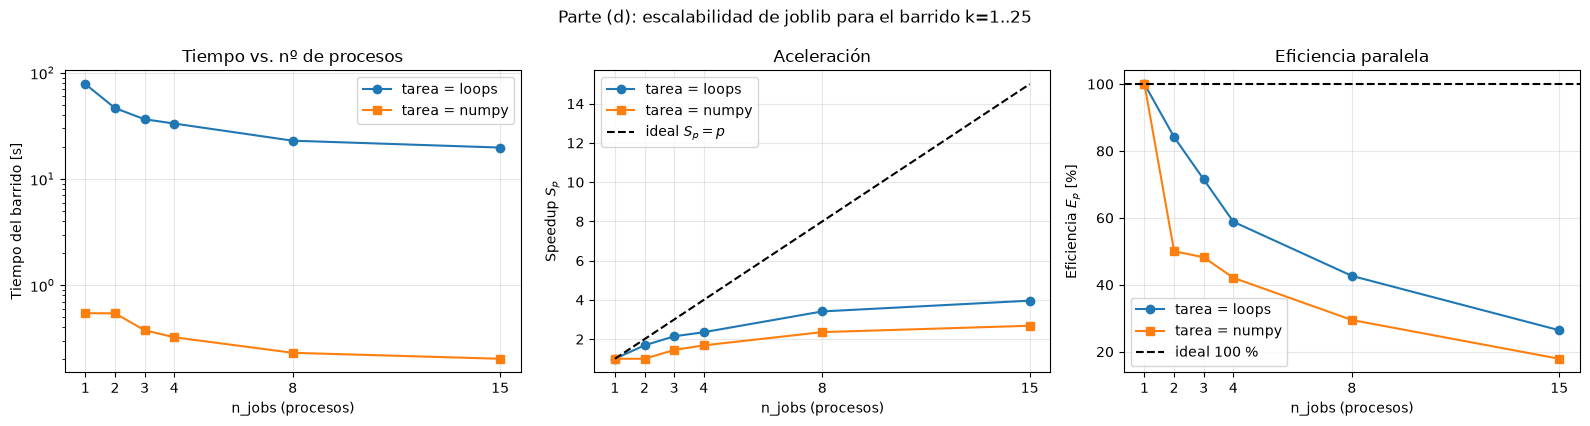

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
P = np.array(n_jobs_list)

for impl, mk in [("loops",'o-'), ("numpy",'s-')]:
    t = np.array([timings[impl][p] for p in n_jobs_list])
    axes[0].plot(P, t, mk, label=f'tarea = {impl}')
    axes[1].plot(P, t[0]/t, mk, label=f'tarea = {impl}')
    axes[2].plot(P, (t[0]/t)/P*100, mk, label=f'tarea = {impl}')

axes[0].set_yscale('log'); axes[0].set_ylabel('Tiempo del barrido [s]')
axes[0].set_title('Tiempo vs. nº de procesos')
axes[1].plot(P, P, 'k--', label='ideal $S_p=p$'); axes[1].set_ylabel('Speedup $S_p$')
axes[1].set_title('Aceleración')
axes[2].axhline(100, color='k', ls='--', label='ideal 100 %'); axes[2].set_ylabel('Eficiencia $E_p$ [%]')
axes[2].set_title('Eficiencia paralela')
for ax in axes:
    ax.set_xlabel('n_jobs (procesos)'); ax.grid(alpha=.3); ax.legend(); ax.set_xticks(P)
plt.suptitle('Parte (d): escalabilidad de joblib para el barrido k=1..25')
plt.tight_layout(); plt.show()

### 5.6 Costo por tarea: el desbalance de carga

El barrido $k=1,\dots,25$ tiene tareas de **costo muy desigual** (correr k-means con $k=25$ cuesta
mucho más que con $k=1$). Según la Clase 05, el tiempo total lo determina el worker más lento, así que
este desbalance es una de las razones por las que la eficiencia no llega al 100 %.

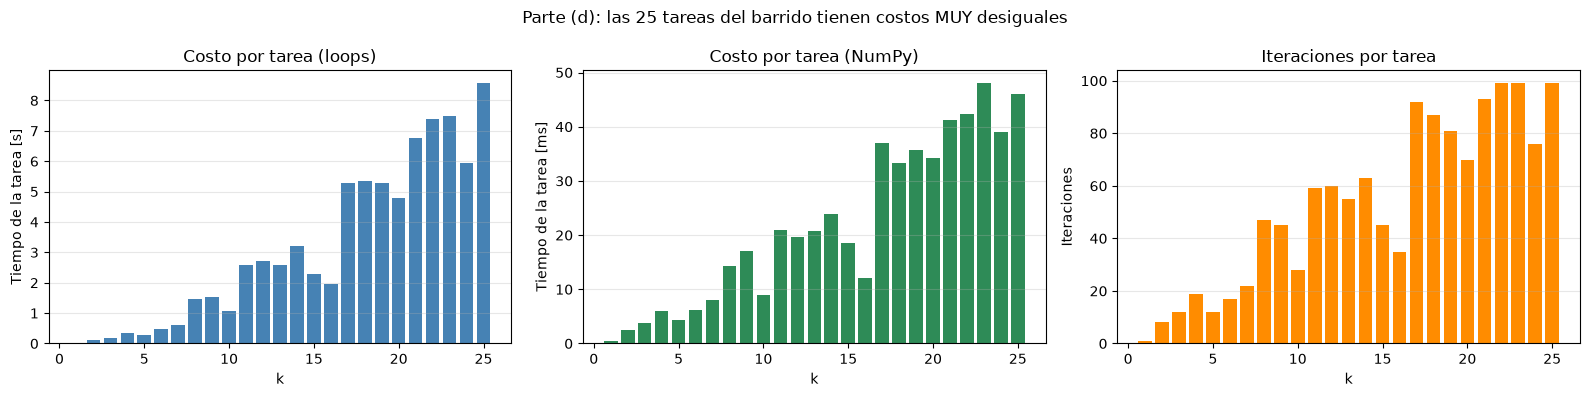

                                  loops          NumPy
------------------------------------------------------
tarea más barata               0.0135 s         0.41 ms
tarea más costosa              8.5641 s        48.00 ms
razón máx/mín                   634.0x        116.2x
suma de las 25 tareas          78.271 s        544.1 ms
------------------------------------------------------

Cota inferior del barrido con loops vs. lo medido:
   p   cota [s]   medido [s]    brecha
--------------------------------------
   1      78.27        78.27     1.00x
   2      39.14        46.50     1.19x
   3      26.09        36.50     1.40x
   4      19.57        33.26     1.70x
   8       9.78        22.93     2.34x
  15       8.56        19.76     2.31x


In [24]:
t_loop  = np.array(per_task["loops"])
t_np    = np.array(per_task["numpy"])
it_task = np.array([s["iterations"] for s in sweep])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(ks, t_loop, color='steelblue')
axes[0].set_ylabel('Tiempo de la tarea [s]');  axes[0].set_title('Costo por tarea (loops)')
axes[1].bar(ks, t_np*1000, color='seagreen')
axes[1].set_ylabel('Tiempo de la tarea [ms]'); axes[1].set_title('Costo por tarea (NumPy)')
axes[2].bar(ks, it_task, color='darkorange')
axes[2].set_ylabel('Iteraciones');             axes[2].set_title('Iteraciones por tarea')
for ax in axes: ax.set_xlabel('k'); ax.grid(alpha=.3, axis='y')
plt.suptitle('Parte (d): las 25 tareas del barrido tienen costos MUY desiguales')
plt.tight_layout(); plt.show()

print(f"{'':24s} {'loops':>14} {'NumPy':>14}")
print("-"*54)
print(f"{'tarea más barata':24s} {t_loop.min():12.4f} s {t_np.min()*1000:12.2f} ms")
print(f"{'tarea más costosa':24s} {t_loop.max():12.4f} s {t_np.max()*1000:12.2f} ms")
print(f"{'razón máx/mín':24s} {t_loop.max()/t_loop.min():12.1f}x {t_np.max()/t_np.min():12.1f}x")
print(f"{'suma de las 25 tareas':24s} {t_loop.sum():12.3f} s {t_np.sum()*1000:12.1f} ms")
print("-"*54)

# Cota inferior del barrido con p workers (Clase 05): ni el reparto perfecto puede
# bajar de max( tarea más larga , trabajo total / p ).
print(f"\nCota inferior del barrido con loops vs. lo medido:")
print(f"{'p':>4} {'cota [s]':>10} {'medido [s]':>12} {'brecha':>9}")
print("-"*38)
for p_ in n_jobs_list:
    cota = max(t_loop.max(), t_loop.sum()/p_)
    real = timings['loops'][p_]
    print(f"{p_:>4} {cota:>10.2f} {real:>12.2f} {real/cota:>8.2f}x")

RESULTS["task_imbalance"]   = float(t_loop.max()/t_loop.min())
RESULTS["t_task_sum_loops"] = float(t_loop.sum())
RESULTS["t_task_max_loops"] = float(t_loop.max())

In [25]:
# Overhead de joblib: costo de crear procesos medido con una tarea trivial
def trivial(i):
    return os.getpid()

t0 = time.perf_counter(); Parallel(n_jobs=1, backend="loky")(delayed(trivial)(i) for i in range(25))
t_ov1 = time.perf_counter()-t0
t0 = time.perf_counter(); Parallel(n_jobs=4, backend="loky")(delayed(trivial)(i) for i in range(25))
t_ov4 = time.perf_counter()-t0

print(f"Overhead de joblib con 25 tareas triviales:")
print(f"   n_jobs=1 : {t_ov1*1000:8.1f} ms")
print(f"   n_jobs=4 : {t_ov4*1000:8.1f} ms")
print(f"\nComparación con el trabajo útil del barrido:")
print(f"   barrido NumPy (serial)  : {t_sweep_serial_numpy*1000:8.1f} ms")
print(f"   barrido loops (serial)  : {timings['loops'][1]*1000:8.1f} ms")
print(f"\n=> El overhead es {t_ov4/t_sweep_serial_numpy*100:.0f} % del barrido NumPy, "
      f"pero solo {t_ov4/timings['loops'][1]*100:.2f} % del barrido con loops.")
RESULTS["t_overhead_njobs4"] = t_ov4; RESULTS["t_overhead_njobs1"] = t_ov1

Overhead de joblib con 25 tareas triviales:
   n_jobs=1 :      0.3 ms
   n_jobs=4 :    282.5 ms

Comparación con el trabajo útil del barrido:
   barrido NumPy (serial)  :    576.1 ms
   barrido loops (serial)  :  78273.8 ms

=> El overhead es 49 % del barrido NumPy, pero solo 0.36 % del barrido con loops.


In [26]:
# Guardar todas las mediciones (se usan en el informe de la sección 6)
with open("resultados.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("Mediciones guardadas en resultados.json")
print(json.dumps({k_: v for k_, v in RESULTS.items()
                  if k_ in ('t_loops_best','t_numpy_best','speedup_vec','k_elbow',
                            'task_imbalance','n_pids_njobs4')}, indent=2))

Mediciones guardadas en resultados.json
{
  "t_loops_best": 0.27284666686318815,
  "t_numpy_best": 0.004108750028535724,
  "speedup_vec": 66.40624641758147,
  "k_elbow": 10,
  "n_pids_njobs4": 4,
  "task_imbalance": 633.9772427329555
}


---

# 6. Informe y discusión de resultados

Todas las cifras de esta sección se generan automáticamente a partir de las mediciones de
**esta misma ejecución** (`resultados.json`), por lo que no pueden quedar desactualizadas. Los tiempos
varían algunos puntos porcentuales entre corridas; las conclusiones no dependen de esa variación.

## Resumen de las mediciones

| Magnitud | Valor |
|---|---|
| Equipo | Apple M5 Pro, con **15 núcleos físicos** (5 *performance* + 10 *efficiency*), 15 lógicos |
| Base de datos | 10,000 puntos, 2 dimensiones, 10 grupos generados (`make_blobs`) |
| k de las partes (a)–(c) | 5 (converge en 12 iteraciones) |
| (a) k-means con *loops* | **0.2728 s** (2,274 ns por punto y por iteración) |
| (b) k-means vectorizado | **0.0041 s** (34.2 ns por punto y por iteración) |
| Aceleración por vectorizar | **66.4×** |
| Consistencia (a) vs (b) | etiquetas **idénticas** (100.0000 %), diferencia máxima en centros **0.0** |
| Codo del barrido k = 1…25 | **k = 10** (coincide con los 10 grupos generados) |
| Barrido serial k = 1…25 | 0.576 s (NumPy) · 78.27 s (*loops*) |
| `joblib`, tarea = *loops* | 78.27 s → **19.76 s** con 15 procesos (**3.96×**) |
| `joblib`, tarea = NumPy | 0.544 s → **0.203 s** con 15 procesos (**2.68×**) |

## (1) ¿Paraleliza el código de Canvas alguna parte del algoritmo?

**No. El código de Canvas es completamente secuencial.** No se trata de una impresión: se midió
(§2.3 y §4.2).

| Evidencia | Medición |
|---|---|
| Procesos de Python | **1** (sin procesos hijos) |
| Hilos creados por el algoritmo | **0** (los 16 hilos observados son del *kernel* de Jupyter en reposo, más 1 del medidor) |
| Uso de CPU del proceso | **99.9 % promedio**, 100.8 % máximo, es decir **≈ 1 núcleo** |
| Capacidad de la máquina | 1500 % (15 núcleos) → se aprovecha el **6.7 %** |

**Por qué.** El algoritmo está escrito como *loops* de Python puro sobre los `n` puntos, y en CPython
el **GIL** permite que **solo un hilo ejecute *bytecode* a la vez** (Clase 07). Aunque se crearan
hilos, no habría paralelismo de cómputo. El código tampoco llama a rutinas compiladas que liberen el
GIL de forma significativa: las únicas operaciones de NumPy están **dentro** del loop por punto
(`sum_of_locations[cluster[p], :] += dataset[p, :]` opera sobre **2 elementos**), de modo que aportan
*overhead* de interpretación en lugar de eliminarlo.

**Dos matices honestos:**

* El *hardware* **sí** paraleliza internamente: un núcleo moderno es **superescalar y segmentado**
  (*pipelining*, IPC > 1, Clase 03). Pero eso es paralelismo **a nivel de instrucción**, lo maneja el
  procesador y no el programa, y aquí está limitado por las dependencias y por el *overhead* del
  intérprete.
* La única parte del ejemplo que **sí** está vectorizada es `calc_inertia`, que usa
  `np.linalg.norm(..., axis=1)` sobre un *slice* del arreglo. Pero está **fuera** del ciclo iterativo
  y no afecta el costo del algoritmo.

## (2) Diferencia de tiempo entre las dos variantes, y por qué

La versión vectorizada es **66.4× más rápida** (0.2728 s → 0.0041 s con n = 10,000 y
k = 5). La aceleración se mantiene **aproximadamente constante** (entre 44× y
73×) para n entre 1,000 y 40,000 (§4.1): **la
vectorización no cambia la complejidad** (ambas son O(n·k·iteraciones)) sino la **constante** que
multiplica a esa complejidad.

El dato más elocuente es el costo **por punto y por iteración**:

| Implementación | Costo por punto · iteración |
|---|---|
| (a) *loops* de Python | **2,274 ns** |
| (b) NumPy / SciPy | **34.2 ns** |

Las razones, en orden de importancia:

1. **Interpretado vs. compilado (Clase 04/08).** Cada iteración del loop de Python paga despacho de
   *bytecode*, creación de objetos `float`, verificación de tipos y de índices. La versión NumPy hace
   **una sola** llamada a `cdist`, y todo el trabajo numérico ocurre dentro de código compilado.
2. **Pipelining (Clase 03).** El código compilado de SciPy ejecuta la **misma instrucción sobre
   muchos datos independientes**, que es justamente el caso favorable para que el *pipeline* del
   procesador se mantenga lleno y la FPU produzca un resultado por ciclo. En el *loop* de Python cada
   operación aritmética está rodeada de trabajo del intérprete, que rompe esa regularidad.
3. **Localidad de datos y línea de caché (Clase 06).** `dataset` es un arreglo contiguo de NumPy.
   `cdist` lo recorre secuencialmente, de modo que cada línea de caché (64–128 bytes, 8–16 *floats*)
   se aprovecha por completo. El *loop* de Python accede `dataset[p,0]` y `dataset[p,1]` elemento por
   elemento, creando un escalar de Python en cada acceso: paga la latencia sin reutilizar la línea.
4. **El chequeo de convergencia.** El original recorre los n puntos comparando etiquetas una por una;
   la versión vectorizada usa `np.array_equal`, que es una comparación compilada.
5. **Algo de paralelismo de hilos.** En §4.2 la versión NumPy llegó a un **máximo de
   248 % de CPU** (frente a 100 % de la versión con
   *loops*), lo que indica que las rutinas compiladas **sí** usan más de un hilo en algunos momentos.
   En este equipo NumPy está compilado contra **accelerate** (Apple Accelerate), que administra sus hilos
   internamente. Con todo, el promedio es ≈ 100 %, así que la mayor parte de la ganancia es por
   eficiencia secuencial, no por paralelismo.

**Verificación de que son equivalentes.** No basta con que sea más rápido: las etiquetas finales son
**idénticas** (coincidencia 100.0000 %), la diferencia máxima entre centros es
**exactamente 0.0**, y ambas convergen en las **mismas 12 iteraciones**. La
inercia vectorizada coincide con la función de Canvas con un error relativo del orden de 10⁻¹⁶
(precisión de máquina).

## (3) Tiempo de cómputo según el número de procesos en `joblib`

Se corrió el barrido completo k = 1,…,25 con `n_jobs` ∈ {1, 2, 3, 4, 8, 15}, usando el
*backend* `loky` (procesos independientes = paradigma *multiprocessing*). Se verificó que
**efectivamente usa procesos distintos**: con `n_jobs=4` se observaron 4 PID de
*workers*, todos **distintos del proceso padre**, y las 25 inercias resultaron idénticas a las del
barrido serial.

| `n_jobs` | Tarea = ***loops*** | Speedup | Eficiencia | Tarea = **NumPy** | Speedup | Eficiencia |
|---|---|---|---|---|---|---|
| 1 | 78.27 s | 1.00× | 100.0 % | 0.544 s | 1.00× | 100.0 % |
| 2 | 46.50 s | 1.68× | 84.2 % | 0.544 s | 1.00× | 50.0 % |
| 3 | 36.50 s | 2.14× | 71.5 % | 0.376 s | 1.45× | 48.2 % |
| 4 | 33.26 s | 2.35× | 58.8 % | 0.323 s | 1.68× | 42.1 % |
| 8 | 22.93 s | 3.41× | 42.7 % | 0.231 s | 2.36× | 29.5 % |
| 15 | 19.76 s | 3.96× | 26.4 % | 0.203 s | 2.68× | 17.9 % |

### Por qué la tarea con *loops* escala y la tarea con NumPy casi no

La diferencia está en la **razón entre trabajo útil y *overhead***. El costo de crear y alimentar los
procesos se midió por separado con 25 tareas triviales: **283 ms** con `n_jobs=4`.

| | Trabajo útil del barrido | *Overhead* medido | *Overhead* relativo |
|---|---|---|---|
| Tarea = *loops* | 78,274 ms | 283 ms | **0.36 %** → despreciable |
| Tarea = NumPy | 576 ms | 283 ms | **49 %** → domina |

* Con **tarea = *loops***, cada tarea dura en promedio ≈ 3.1 s de cómputo *cpu-bound* en
  Python puro. Como cada *worker* es un **proceso** con su propio intérprete y su propio GIL, el
  paralelismo es real y el *overhead* es irrelevante frente al trabajo. Por eso hay speedup efectivo.
* Con **tarea = NumPy**, cada tarea dura ≈ 22 ms, menos que lo que cuesta lanzar un
  proceso y serializar sus argumentos. De hecho con `n_jobs=2` el speedup es
  **1.00×**: paralelizar **casi no aporta nada**. Además `dataset` pesa **156 KiB**,
  por debajo del umbral de 1 MB con que `joblib` usa *memmap*, así que el arreglo se **serializa con
  `pickle` y se copia a cada tarea** (Clase 04).

> **Conclusión práctica:** paralelizar con procesos solo conviene cuando la tarea es **suficientemente
> grande** respecto al costo de crearla. Para el barrido vectorizado lo más rápido en términos
> absolutos sigue siendo **optimizar el algoritmo**: el barrido NumPy **serial** (0.58 s) es
> **34× más rápido** que el barrido con *loops* repartido en 15 procesos
> (19.76 s). *El algoritmo importa más que el paralelismo* (Clase 08).

### Por qué la eficiencia cae incluso en el caso favorable

Aun con tarea = *loops*, el speedup se satura en 3.96× con 15 procesos
(eficiencia 26 %). Hay tres causas, todas medidas:

**(i) Desbalance de carga (Clase 05).** Las 25 tareas tienen costos extremadamente desiguales: de
**0.0135 s** (k = 1) a **8.5641 s** (k = 25), una razón de
**634×**. El tiempo total nunca puede ser menor que
`max(tarea más larga, trabajo total / p)`:

| p | Cota inferior | Medido | Brecha |
|---|---|---|---|
| 2 | 39.14 s | 46.50 s | 1.19× |
| 3 | 26.09 s | 36.50 s | 1.40× |
| 4 | 19.57 s | 33.26 s | 1.70× |
| 8 | 9.78 s | 22.93 s | 2.34× |
| 15 | 8.56 s | 19.76 s | 2.31× |

A partir de p = 15 la cota la fija **una sola tarea**: la de k = 25 dura 8.56 s, que es
el **10.9 %** de todo el trabajo. Esa tarea indivisible se comporta como una **fracción
serial** y, por la ley de Amdahl, acota el speedup en **S∞ ≤ 1/0.109 ≈ 9.1×**, *sin
importar cuántos procesos se usen*. Invirtiendo Amdahl a partir de los datos medidos se obtiene una
fracción serial efectiva de **f ≈ 23–19 %**, del mismo orden.

**(ii) Los núcleos no son equivalentes.** Este equipo tiene **5 núcleos *performance* y 10
*efficiency***. Hasta p = 5 se usan casi solo núcleos rápidos y la eficiencia se mantiene alta
(84 % con p = 2). Al pasar de 5 procesos se empieza a repartir trabajo a núcleos
*efficiency*, bastante más lentos: el *worker* que cae en un núcleo lento **retrasa todo el barrido**,
porque el tiempo total lo determina el más lento. En la ley de Amdahl el parámetro `p` supone
*workers* **idénticos**; en una arquitectura heterogénea ese supuesto no se cumple, y es la razón
principal de la brecha respecto de la cota para p = 8 y p = 15.

**(iii) *Overhead* y parte serial del padre.** Crear procesos, serializar `dataset` 25 veces y
recolectar los resultados en el proceso padre es trabajo que no se paraleliza.

**Sobre la *oversubscription* (Clase 04).** NumPy puede abrir hilos dentro de cada proceso; con p
procesos × varios hilos se puede superar el número de núcleos. En este equipo NumPy usa **accelerate**,
que no expone su *pool* de hilos a `threadpoolctl` (§1), así que no se puede limitar por esa vía; el
efecto aquí es menor porque `cdist` es esencialmente de un hilo.

## (4) ¿Cuántos núcleos físicos tiene el computador?

**15 núcleos físicos**, en un **Apple M5 Pro**, distribuidos de forma **heterogénea**:

* **5 núcleos *performance*** (alto rendimiento),
* **10 núcleos *efficiency*** (bajo consumo).

También tiene **15 núcleos lógicos**: en Apple Silicon **no hay hyperthreading/SMT**, así que hay
exactamente **un hilo de hardware por núcleo físico** (a diferencia de un procesador x86 con SMT,
donde los núcleos lógicos serían 30). Esto es relevante para interpretar los resultados de la
pregunta (3): el límite de paralelismo real son 15 *workers*, y además esos 15 **no son
equivalentes entre sí**.

Verificado con `psutil.cpu_count(logical=False)` y `sysctl hw.perflevel{0,1}.physicalcpu` en §1.

## 7. Dos observaciones adicionales

### 7.1 El código original falla con conglomeraciones vacías

El ejemplo de Canvas calcula el nuevo centro como
`sum_of_locations[c,0] / number_of_points_in_cluster[c]`. Si una conglomeración queda **vacía**, el
divisor es 0, el resultado es `nan` y eso contamina todas las iteraciones siguientes.

Con la inicialización del enunciado (todos los centros en el segmento 0 < x < 1, y = 0) esto **ocurre
en la práctica**: en el barrido k = 1,…,25 se detectaron conglomeraciones vacías para
**k = 11, 15, 23**. Por eso ambas implementaciones de este notebook
**mantienen el centro anterior** cuando una conglomeración queda vacía (la convención usual) y
**cuentan** los casos para poder reportarlos. Sin esa corrección, el gráfico del codo tendría valores
`nan`.

Además, para **k = 22, 23, 25** el algoritmo **no converge** en las 100
iteraciones del ejemplo y se detiene por el máximo. Es esperable con una inicialización tan mala y con
k mayor que el número real de grupos (10): los centros sobrantes quedan oscilando entre puntos de
frontera. La inercia a 100 iteraciones ya está prácticamente estabilizada, así que el gráfico del codo
no se ve afectado.

### 7.2 El método del codo: cuidado con el criterio

El enunciado pide buscar "el punto de inflexión donde la inercia ya no se reduce de manera
significativa". Se usaron **dos criterios cuantitativos**, y ambos coinciden en **k = 10**,
que es exactamente el número de grupos que generó `make_blobs`:

* **cuerda sobre log(I)** (el punto más alejado de la recta que une los extremos): k = 10;
* **primera ganancia marginal < 10 %**: k = 10. La inercia cae 18.1 % al pasar de
  k = 9 a k = 10, y solo 4.2 % al pasar de k = 10 a k = 11.

En cambio, el criterio ingenuo de **máxima segunda diferencia** da **k = 2**, que es
engañoso: como la inercia cae de forma muy abrupta para k pequeños, la mayor curvatura absoluta está
siempre al principio de la curva. Es un buen recordatorio de que el "codo" hay que definirlo de forma
**relativa**, no absoluta.

### 7.3 Sobre la copia de variables (observación del enunciado)

Se revisó explícitamente el riesgo de *aliasing* que advierte el enunciado:

* En la versión con *loops*, `old_centers = history_of_centers[-1]` es una **referencia**, pero nunca
  se modifica `old_centers` en el lugar: `new_centers` se crea como un `np.zeros` **nuevo** en cada
  iteración. No hay *aliasing*.
* En la versión vectorizada se usa `new_centers = centers.copy()` antes de modificar, de modo que la
  asignación por máscara `new_centers[nonempty] = ...` no altera el arreglo anterior.
* El historial guarda arreglos distintos en cada iteración, lo que permitió graficar la trayectoria de
  los centros en §2.2.

Por eso no fue necesario `copy.deepcopy`: basta `.copy()` de NumPy, que además es más barato porque
los arreglos contienen solo números y no objetos anidados.

---

## 8. Conclusiones

1. El código entregado en Canvas **no paraleliza nada**: usa 1 proceso, 1 hilo de cómputo y el
   6.7 % de la máquina.
2. **Vectorizar** es la optimización de mayor retorno y la más simple: **66.4× más rápido** sin
   cambiar el resultado (etiquetas idénticas). Mejora la constante, no la complejidad.
3. **Paralelizar con `joblib` solo rinde si la tarea es grande.** Con tareas de ≈ 3.1 s
   (*loops*) se logra 3.96× con 15 procesos; con tareas de
   ≈ 22 ms (NumPy) el *overhead* es el 49 % del trabajo y con 2
   procesos el speedup es de apenas 1.00× (casi nulo).
4. La eficiencia paralela cae por **desbalance de carga** (tareas que difieren
   634×; una sola tarea es el 10.9 % del trabajo total →
   S∞ ≲ 9.1×) y porque los **15 núcleos no son equivalentes** (5 *performance* + 10
   *efficiency*), lo que rompe el supuesto de *workers* idénticos de la ley de Amdahl.
5. El orden correcto es **primero el algoritmo, después la vectorización y al final el paralelismo**:
   el barrido vectorizado **serial** (0.58 s) le gana por **34×** al
   barrido con *loops* repartido en **15 procesos** (19.76 s).

## Declaración de uso de herramientas de IA

Se utilizó un asistente de IA (Claude, Anthropic) como apoyo en la vectorización del algoritmo
(`scipy.spatial.distance.cdist`, `np.argmin`, `np.bincount`, `np.add.at`), en la estructura del código
de medición y los gráficos, y en la redacción de este informe. El diseño experimental, la ejecución en
mi equipo, la verificación de consistencia entre implementaciones y la interpretación de los
resultados son propios. Todo el código fue revisado y ejecutado por mí y soy responsable del contenido
entregado.